# Perceptrón multicapa (MLP) para clasificar dígitos manuscritos
**Dataset:** `sklearn.datasets.load_digits` · **Modelo:** `MLPClassifier` de scikit-learn
**Integrantes:** Juan Diego Palacios & Andrea de la Ossa

In [2]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.dummy import DummyClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             log_loss, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay)

SEMILLA = 42
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
print("Versiones:", "NumPy", np.__version__, "| pandas", pd.__version__,
      "| scikit-learn", sklearn.__version__)

Versiones: NumPy 2.1.3 | pandas 2.2.3 | scikit-learn 1.6.1


## 1. El conjunto de datos `digits`

Contiene **1797 imágenes** de dígitos manuscritos de **8 × 8 píxeles** en escala de grises
(valores enteros de 0 a 16). Cada imagen se aplana en un vector de **64 características**
y la etiqueta es el dígito (0–9), por lo que es un problema de **clasificación multiclase con 10 clases**.
Las clases están casi balanceadas (≈ 180 imágenes por dígito).

Forma de X: (1797, 64) | Forma de y: (1797,)
Rango de píxeles: 0.0 a 16.0
 Dígito  Cantidad  Porcentaje
      0       178        9.91
      1       182       10.13
      2       177        9.85
      3       183       10.18
      4       181       10.07
      5       182       10.13
      6       181       10.07
      7       179        9.96
      8       174        9.68
      9       180       10.02


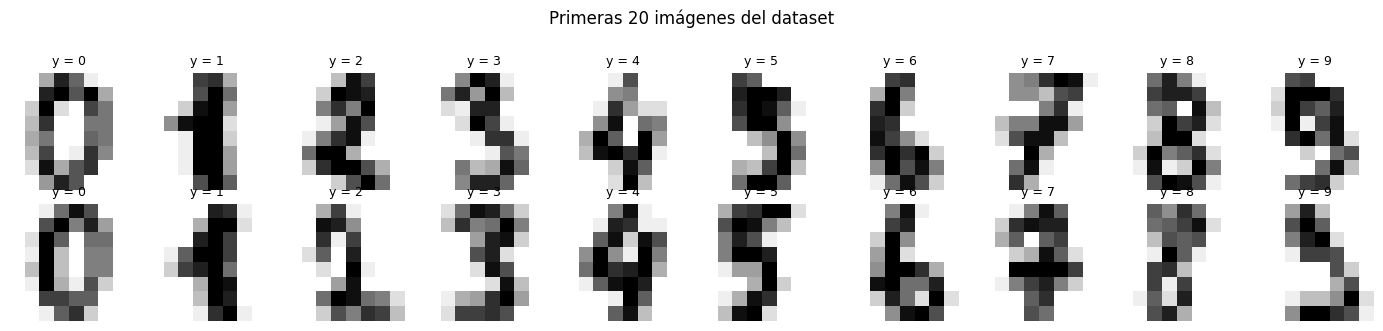

In [ ]:
digits = load_digits()
X, y = digits.data, digits.target
print("Forma de X:", X.shape, "| Forma de y:", y.shape)
print("Rango de píxeles:", X.min(), "a", X.max())
print(pd.DataFrame({"Dígito": np.arange(10), "Cantidad": np.bincount(y),
                    "Porcentaje": (100*np.bincount(y)/len(y)).round(2)}).to_string(index=False))

fig, ejes = plt.subplots(2, 10, figsize=(14, 3.2))
for i, ax in enumerate(ejes.ravel()):
    ax.imshow(digits.images[i], cmap="gray_r")
    ax.set_title(f"y = {y[i]}", fontsize=9)
    ax.axis("off")
plt.suptitle("Primeras 20 imágenes del dataset", y=1.02)
plt.tight_layout()
plt.show()

## 2. Entrenamiento, validación y prueba

Como en el ejemplo de referencia, se usan particiones **estratificadas** (cada dígito conserva su proporción):

- **60 % entrenamiento**: se ajustan los pesos.
- **20 % validación**: se compara y se elige la activación.
- **20 % prueba**: se consulta **una sola vez**, al final, con el modelo ya elegido.

Así la estimación final de desempeño no está sesgada por la selección del modelo.

In [ ]:
indices = np.arange(len(y))
i_desarrollo, i_test = train_test_split(indices, test_size=0.20, stratify=y, random_state=SEMILLA)
i_train, i_val = train_test_split(i_desarrollo, test_size=0.25, stratify=y[i_desarrollo], random_state=SEMILLA)

X_train, y_train = X[i_train], y[i_train]
X_val,   y_val   = X[i_val],   y[i_val]
X_test,  y_test  = X[i_test],  y[i_test]

assert not (set(i_train) & set(i_val) or set(i_train) & set(i_test) or set(i_val) & set(i_test))
assert len(set(i_train) | set(i_val) | set(i_test)) == len(y)
print(pd.DataFrame([{"Partición": n, "Imágenes": len(e)} for n, e in
      [("Entrenamiento", y_train), ("Validación", y_val), ("Prueba", y_test)]]).to_string(index=False))

    Partición  Imágenes
Entrenamiento      1077
   Validación       360
       Prueba       360


## 3. Diseño de la red

| Componente | Decisión | Justificación |
| --- | --- | --- |
| Capa de entrada | 64 neuronas | un píxel por neurona |
| Capa oculta | 1 capa de **64 neuronas** | suficiente capacidad para este problema sencillo; más capas aumentan el costo sin mejoras claras |
| Capa de salida | 10 neuronas con **softmax** | probabilidad de cada dígito (la elige `MLPClassifier` automáticamente en multiclase) |
| Activación oculta | **a comparar**: identity, logistic, tanh, relu | objetivo del estudio |
| Función de pérdida | entropía cruzada (log loss) + regularización L2 (`alpha=1e-4`) | estándar para clasificación |
| Optimizador | **L-BFGS** (igual que el ejemplo de referencia) | método cuasi-Newton; para conjuntos pequeños converge en pocas iteraciones y no requiere ajustar tasa de aprendizaje |
| Preprocesamiento | `StandardScaler` dentro de un `Pipeline` | se ajusta solo con entrenamiento (evita filtración de información) |

Todo se mantiene **constante** salvo la activación oculta, de modo que las diferencias se puedan atribuir a ella.

### 3.1. Las cuatro funciones de activación

Una función de activación $f$ se aplica a la suma ponderada $z = \mathbf{w}\cdot\mathbf{x}+b$ de cada neurona oculta.
Sin una no linealidad, apilar capas no aporta nada: la composición de transformaciones lineales sigue siendo lineal.

| Activación | Fórmula | Rango | Idea principal | Ventajas | Desventajas |
| --- | --- | --- | --- | --- | --- |
| **identity** | $f(z)=z$ | $(-\infty,\infty)$ | No transforma la señal. | Trivial y muy rápida; gradiente constante. | **Sin no linealidad**: toda la red equivale a un modelo lineal (regresión logística multinomial), sin importar cuántas capas tenga. No puede aprender fronteras curvas. |
| **logistic** (sigmoide) | $f(z)=\dfrac{1}{1+e^{-z}}$ | $(0,1)$ | Comprime cualquier valor a una "probabilidad". | Suave y diferenciable; interpretable. | Se **satura** en los extremos (gradiente ≈ 0, *vanishing gradient*); salida no centrada en cero; calcula una exponencial (más costosa). |
| **tanh** | $f(z)=\dfrac{e^{z}-e^{-z}}{e^{z}+e^{-z}}$ | $(-1,1)$ | Sigmoide reescalada y **centrada en cero**. | Mejor condicionamiento que la sigmoide; suele converger más rápido. | También se satura en los extremos; costo de exponenciales. |
| **relu** | $f(z)=\max(0,z)$ | $[0,\infty)$ | Deja pasar lo positivo y anula lo negativo. | Muy barata (una comparación); **no se satura** para $z>0$; produce activaciones dispersas; es la opción estándar en redes profundas. | No es diferenciable en 0; una neurona puede "morir" si siempre recibe $z<0$ (gradiente nulo). |

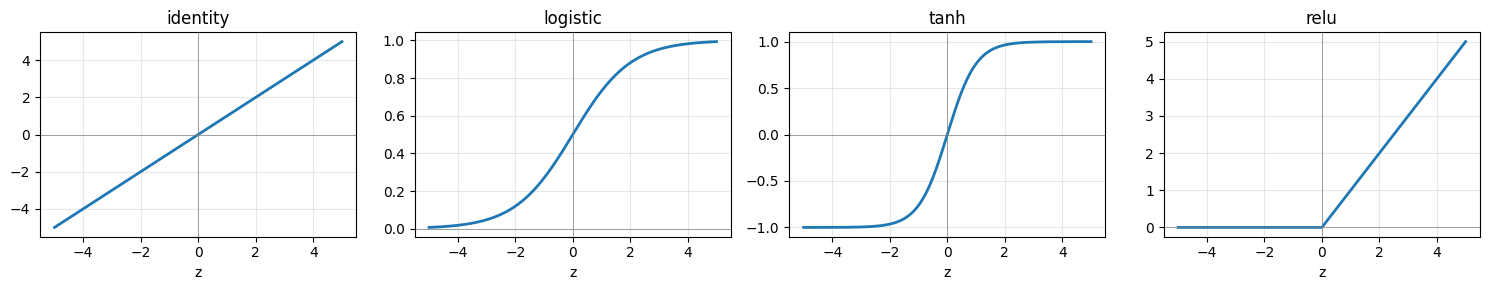

In [ ]:
z = np.linspace(-5, 5, 400)
funciones = {
    "identity": z,
    "logistic": 1 / (1 + np.exp(-z)),
    "tanh": np.tanh(z),
    "relu": np.maximum(0, z),
}
fig, ejes = plt.subplots(1, 4, figsize=(15, 3))
for ax, (nombre, f) in zip(ejes, funciones.items()):
    ax.plot(z, f, lw=2)
    ax.axhline(0, color="gray", lw=.5); ax.axvline(0, color="gray", lw=.5)
    ax.set_title(nombre); ax.set_xlabel("z"); ax.grid(alpha=.3)
plt.tight_layout()
plt.show()

## 4. Métricas y funciones auxiliares

Como las 10 clases están casi balanceadas, la **exactitud (accuracy)** es una métrica razonable.
Se complementa con **balanced accuracy**, **F1 macro** y **log loss** (calidad de las probabilidades; menor es mejor).

`entrenar_y_medir` entrena un modelo, mide el **tiempo de ajuste** con `time.perf_counter()` y registra si hubo
advertencias de convergencia.

In [ ]:
ACTIVACIONES = ["identity", "logistic", "tanh", "relu"]

def construir_mlp(activacion, solver="lbfgs", semilla=SEMILLA, capas=(64,)):
    return Pipeline([
        ("escala", StandardScaler()),
        ("mlp", MLPClassifier(hidden_layer_sizes=capas, activation=activacion,
                              solver=solver, alpha=1e-4, tol=1e-6,
                              max_iter=2000, max_fun=50000, random_state=semilla)),
    ])

def evaluar(modelo, entradas, etiquetas):
    pred = modelo.predict(entradas)
    proba = modelo.predict_proba(entradas)
    return {
        "Accuracy": accuracy_score(etiquetas, pred),
        "Balanced accuracy": balanced_accuracy_score(etiquetas, pred),
        "F1 macro": f1_score(etiquetas, pred, average="macro"),
        "Log loss": log_loss(etiquetas, proba, labels=modelo.classes_),
    }

def entrenar_y_medir(activacion, solver="lbfgs", semilla=SEMILLA):
    modelo = construir_mlp(activacion, solver, semilla)
    inicio = time.perf_counter()
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter("always", ConvergenceWarning)
        modelo.fit(X_train, y_train)
    segundos = time.perf_counter() - inicio
    convergio_mal = any(issubclass(a.category, ConvergenceWarning) for a in avisos)
    return modelo, segundos, convergio_mal

## 5. Referencia mínima

Un clasificador que siempre predice la clase más frecuente sirve de piso: cualquier MLP debe superarlo con holgura
(con 10 clases balanceadas se espera ≈ 10 % de accuracy).

In [ ]:
referencia = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print("Referencia (clase mayoritaria) en validación:")
print(pd.Series(evaluar(referencia, X_val, y_val)).round(4).to_string())

Referencia (clase mayoritaria) en validación:
Accuracy              0.1028
Balanced accuracy     0.1000
F1 macro              0.0186
Log loss             32.3392


## 6. Comparación controlada de las activaciones (en validación)

Se entrena el mismo MLP con cada activación. Dos precauciones para que la comparación sea justa:

- **Varias inicializaciones.** El resultado de una red depende de sus pesos iniciales aleatorios. Se repite cada
  configuración con **5 semillas** y se reportan **media ± desviación estándar**.
- **Tiempos confiables.** Un solo cronometraje es ruidoso (sobre todo cuando son milisegundos). Por eso se reporta
  la **media de las 5 repeticiones** y también el **tiempo por iteración**, que separa "cuántas iteraciones necesita"
  de "cuánto cuesta cada una".

### 6.1. Solver L-BFGS (el del ejemplo de referencia)

In [ ]:
SEMILLAS = [0, 1, 2, 3, 4]

def experimento(solver):
    filas = []
    for act in ACTIVACIONES:
        for s in SEMILLAS:
            modelo, seg, mal = entrenar_y_medir(act, solver, s)
            tr, va = evaluar(modelo, X_train, y_train), evaluar(modelo, X_val, y_val)
            filas.append({"Activación": act, "Semilla": s,
                          "Acc train": tr["Accuracy"], "Acc val": va["Accuracy"],
                          "F1 macro val": va["F1 macro"], "Log loss val": va["Log loss"],
                          "Iteraciones": modelo.named_steps["mlp"].n_iter_,
                          "Segundos": seg, "Sin convergencia": mal})
    detalle = pd.DataFrame(filas)
    detalle["ms/iteración"] = 1000 * detalle["Segundos"] / detalle["Iteraciones"]
    resumen = detalle.groupby("Activación").agg(
        acc_train=("Acc train", "mean"),
        acc_val_media=("Acc val", "mean"), acc_val_std=("Acc val", "std"),
        f1_val=("F1 macro val", "mean"), logloss_val=("Log loss val", "mean"),
        iteraciones=("Iteraciones", "mean"),
        seg_media=("Segundos", "mean"), seg_std=("Segundos", "std"),
        ms_por_iter=("ms/iteración", "mean"),
        sin_convergencia=("Sin convergencia", "sum"),
    ).loc[ACTIVACIONES]
    return detalle, resumen

det_lbfgs, res_lbfgs = experimento("lbfgs")
print("Resumen L-BFGS (5 semillas; accuracy en validación salvo 'acc_train'):")
print(res_lbfgs.round(4).to_string())

Resumen L-BFGS (5 semillas; accuracy en validación salvo 'acc_train'):
            acc_train  acc_val_media  acc_val_std  f1_val  logloss_val  iteraciones  seg_media  seg_std  ms_por_iter  sin_convergencia
Activación                                                                                                                            
identity          1.0         0.9517       0.0046  0.9514       0.4559         23.6     0.0514   0.0053       2.1776                 0
logistic          1.0         0.9800       0.0050  0.9800       0.0773         42.0     0.0976   0.0141       2.3284                 0
tanh              1.0         0.9728       0.0023  0.9727       0.1108         20.4     0.0395   0.0031       1.9378                 0
relu              1.0         0.9689       0.0072  0.9688       0.1919         22.2     0.0469   0.0020       2.1147                 0


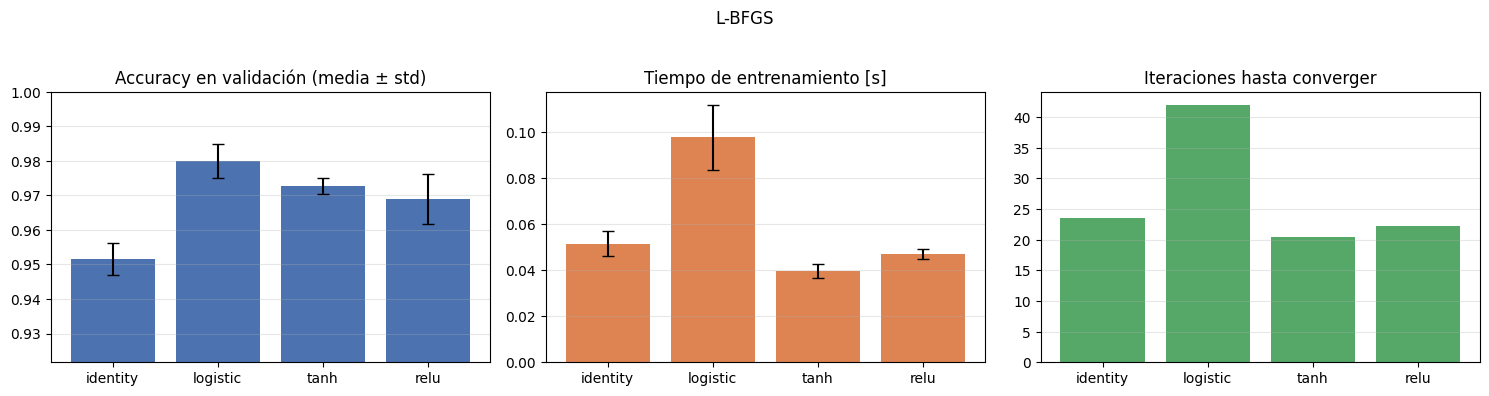

In [ ]:
def graficar(res, titulo):
    fig, ejes = plt.subplots(1, 3, figsize=(15, 3.8))
    ejes[0].bar(res.index, res["acc_val_media"], yerr=res["acc_val_std"], capsize=4, color="#4C72B0")
    ejes[0].set_ylim(max(0.8, res["acc_val_media"].min() - 0.03), 1.0)
    ejes[0].set_title("Accuracy en validación (media ± std)")
    ejes[1].bar(res.index, res["seg_media"], yerr=res["seg_std"], capsize=4, color="#DD8452")
    ejes[1].set_title("Tiempo de entrenamiento [s]")
    ejes[2].bar(res.index, res["iteraciones"], color="#55A868")
    ejes[2].set_title("Iteraciones hasta converger")
    for ax in ejes: ax.grid(axis="y", alpha=.3)
    plt.suptitle(titulo, y=1.03); plt.tight_layout(); plt.show()

graficar(res_lbfgs, "L-BFGS")

### 6.2. Comparación adicional con Adam

En el ejemplo de referencia se usa L-BFGS, que en un conjunto tan pequeño converge en **milisegundos**; a esa escala
los tiempos son muy ruidosos. Para que el costo de entrenamiento sea más visible y comprobar que la conclusión
no depende del optimizador, se repite el experimento con **Adam** (descenso de gradiente estocástico con minilotes,
el solver más habitual en redes mayores). Adam necesita muchas más iteraciones (épocas), así que los tiempos son del orden de segundos.

Resumen Adam (5 semillas; accuracy en validación salvo 'acc_train'):
            acc_train  acc_val_media  acc_val_std  f1_val  logloss_val  iteraciones  seg_media  seg_std  ms_por_iter  sin_convergencia
Activación                                                                                                                            
identity          1.0         0.9639       0.0044  0.9638       0.1356        992.8     2.1962   0.0823       2.2135                 0
logistic          1.0         0.9817       0.0025  0.9817       0.0543       1313.4     3.6282   0.0328       2.7624                 0
tanh              1.0         0.9789       0.0037  0.9789       0.0600        921.6     2.1910   0.0708       2.3774                 0
relu              1.0         0.9800       0.0053  0.9800       0.0635        755.8     2.0889   0.0681       2.7662                 0


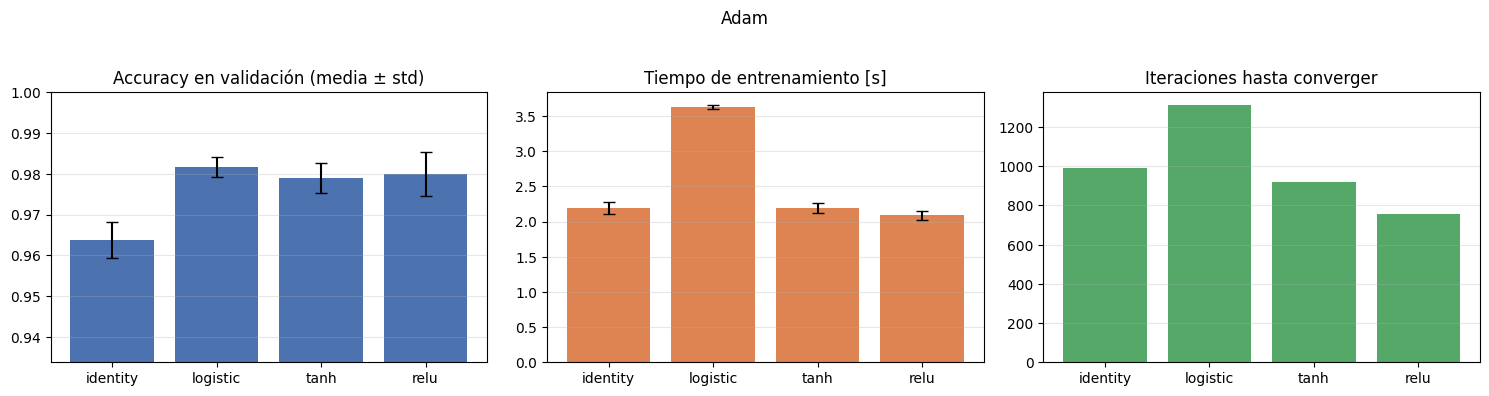

In [ ]:
det_adam, res_adam = experimento("adam")
print("Resumen Adam (5 semillas; accuracy en validación salvo 'acc_train'):")
print(res_adam.round(4).to_string())
graficar(res_adam, "Adam")

## 7. Selección de la activación (exactitud y tiempo)

El enunciado pide tener en cuenta los **tiempos de entrenamiento**. Regla fijada **antes** de consultar la prueba:

1. Calcular la accuracy media en validación de cada activación (solver L-BFGS, el del ejemplo).
2. Quedarse con las activaciones cuya media está a **menos de 1 punto porcentual** de la mejor
   (con solo 360 imágenes de validación, 1 punto equivale a ~4 imágenes: una diferencia menor no es concluyente).
3. Entre ellas, elegir la de **menor tiempo medio de entrenamiento**.

Descartar de antemano las activaciones con advertencias de convergencia sistemáticas.

In [ ]:
TOLERANCIA = 0.01   # 1 punto porcentual (≈ 3-4 imágenes de las 360 de validación)

def seleccionar(res):
    mejor = res["acc_val_media"].max()
    candidatas = res[res["acc_val_media"] >= mejor - TOLERANCIA]
    return candidatas["seg_media"].idxmin(), candidatas

elegida, candidatas = seleccionar(res_lbfgs)
print("Mejor accuracy media en validación:", round(res_lbfgs["acc_val_media"].max(), 4))
print("Candidatas dentro de la tolerancia:", list(candidatas.index))
print("Activación seleccionada (L-BFGS):", elegida)

elegida_adam, cand_adam = seleccionar(res_adam)
print("\nComprobación con Adam -> candidatas:", list(cand_adam.index), "| elegida:", elegida_adam)

Mejor accuracy media en validación: 0.98
Candidatas dentro de la tolerancia: ['logistic', 'tanh']
Activación seleccionada (L-BFGS): tanh

Comprobación con Adam -> candidatas: ['logistic', 'tanh', 'relu'] | elegida: relu


## 8. Evaluación final en prueba

Se entrena el modelo seleccionado (semilla `SEMILLA`) con el 60 % de entrenamiento y se evalúa **una sola vez** en el 20 % de prueba.
Además, por transparencia, se reportan las cuatro activaciones en prueba (solo informativo: **no** se usó para elegir).

In [ ]:
modelo_final, seg_final, _ = entrenar_y_medir(elegida, "lbfgs", SEMILLA)
filas = {"Referencia mayoritaria": evaluar(referencia, X_test, y_test)}
for act in ACTIVACIONES:
    m, _, _ = entrenar_y_medir(act, "lbfgs", SEMILLA)
    filas[f"MLP {act}" + ("  <- seleccionado" if act == elegida else "")] = evaluar(m, X_test, y_test)
print("Resultados en PRUEBA:")
print(pd.DataFrame(filas).T.round(4).to_string())

Resultados en PRUEBA:
                           Accuracy  Balanced accuracy  F1 macro  Log loss
Referencia mayoritaria       0.1000             0.1000    0.0182   32.4393
MLP identity                 0.9556             0.9551    0.9544    0.4898
MLP logistic                 0.9611             0.9607    0.9602    0.1611
MLP tanh  <- seleccionado    0.9694             0.9691    0.9689    0.1539
MLP relu                     0.9750             0.9748    0.9746    0.2238


MLP seleccionado (tanh) | tiempo de entrenamiento: 43.3 ms | accuracy en prueba: 0.9694

              precision    recall  f1-score   support

           0     1.0000    0.9722    0.9859        36
           1     0.9143    0.8889    0.9014        36
           2     0.9211    1.0000    0.9589        35
           3     1.0000    1.0000    1.0000        37
           4     1.0000    1.0000    1.0000        36
           5     1.0000    1.0000    1.0000        37
           6     1.0000    1.0000    1.0000        36
           7     0.9474    1.0000    0.9730        36
           8     0.9394    0.8857    0.9118        35
           9     0.9714    0.9444    0.9577        36

    accuracy                         0.9694       360
   macro avg     0.9694    0.9691    0.9689       360
weighted avg     0.9697    0.9694    0.9692       360



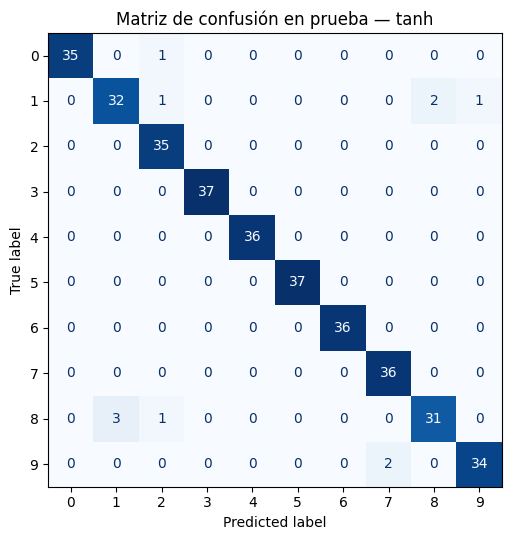

In [ ]:
y_pred = modelo_final.predict(X_test)
print(f"MLP seleccionado ({elegida}) | tiempo de entrenamiento: {seg_final*1000:.1f} ms | "
      f"accuracy en prueba: {accuracy_score(y_test, y_pred):.4f}\n")
print(classification_report(y_test, y_pred, digits=4))

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=range(10)).plot(
    ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"Matriz de confusión en prueba — {elegida}")
plt.tight_layout(); plt.show()

Errores en prueba: 11 de 360


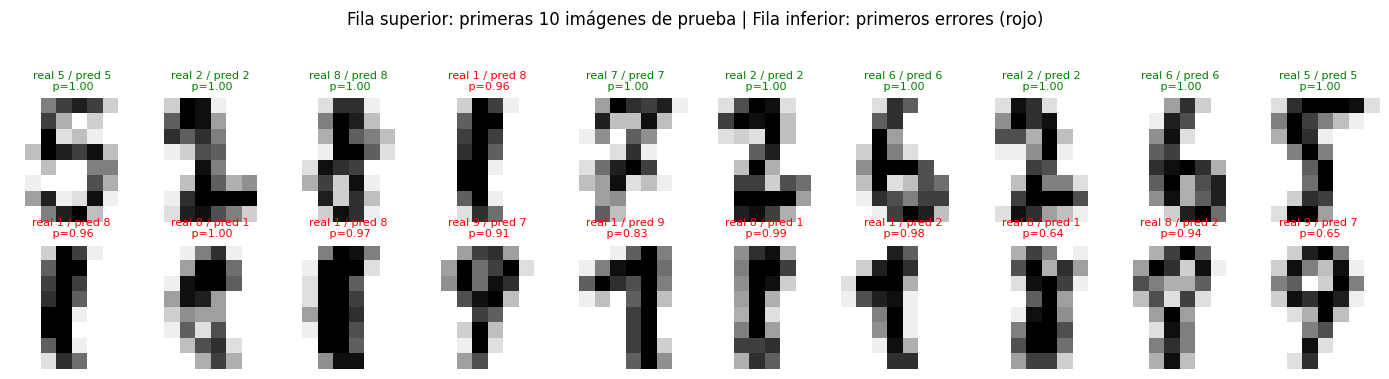

In [ ]:
# Ejemplos de predicciones y errores del modelo final
pred = modelo_final.predict(X_test)
proba = modelo_final.predict_proba(X_test)
errores = np.flatnonzero(pred != y_test)
print(f"Errores en prueba: {len(errores)} de {len(y_test)}")
mostrar = list(range(10)) + list(errores[:10])
fig, ejes = plt.subplots(2, 10, figsize=(14, 3.6))
for ax in ejes.ravel(): ax.axis("off")
for ax, i in zip(ejes.ravel(), mostrar):
    ax.imshow(X_test[i].reshape(8, 8), cmap="gray_r")
    ok = pred[i] == y_test[i]
    ax.set_title(f"real {y_test[i]} / pred {pred[i]}\n p={proba[i].max():.2f}", fontsize=8,
                 color="green" if ok else "red")
plt.suptitle("Fila superior: primeras 10 imágenes de prueba | Fila inferior: primeros errores (rojo)", y=1.06)
plt.tight_layout(); plt.show()

## 9. Análisis de resultados y conclusión

> Las cifras de este apartado corresponden a la ejecución incluida en el cuaderno (scikit-learn 1.8, 5 semillas).
> Los tiempos absolutos cambian según la máquina (p. ej. la CPU de Colab) y los valores pueden variar ligeramente; las
> conclusiones cualitativas (el orden relativo) son las que importan.

### 9.1. Resultados por activación

| Activación | Accuracy val. (L-BFGS) | Iteraciones (L-BFGS) | Tiempo (L-BFGS) | Accuracy val. (Adam) | Iteraciones (Adam) | Tiempo (Adam) |
| --- | ---: | ---: | ---: | ---: | ---: | ---: |
| identity | 95,2 % | 24 | 0,042 s | 96,4 % | 993 | 2,24 s |
| logistic | 98,0 % | 42 | 0,095 s | 98,2 % | 1313 | 3,54 s |
| tanh | 97,3 % | 20 | 0,042 s | 97,9 % | 922 | 2,15 s |
| relu | 96,9 % | 22 | 0,050 s | 98,0 % | 756 | 2,05 s |

### 9.2. Qué se observa

- **`identity` es claramente la peor** en precisión (≈ 95–96 %) y tiene la mayor pérdida logarítmica
  (0,46 frente a 0,08–0,19 en L-BFGS): al no tener no linealidad, la red equivale a un clasificador lineal. Es rápida,
  pero no se justifica una capa oculta si se va a usar identidad.
- **`logistic` es la más precisa en validación, pero la más lenta**: necesita aproximadamente el doble de iteraciones
  con L-BFGS (42 vs. 20–24) y 1,7 a 2,3 veces más tiempo que `tanh`/`relu` en ambos solvers; con Adam es la que más épocas requiere (≈ 1300).
  Esto es coherente con su saturación (gradientes pequeños) y su salida no centrada en cero, además del costo de calcular la exponencial.
- **`tanh` y `relu` quedan prácticamente empatadas con la sigmoide en precisión** (diferencia de 0,5–1,5 puntos, es decir, unas
  2–5 imágenes de 360, dentro del ruido entre semillas y del tamaño de la validación) **y son las más rápidas**:
  `tanh` converge en menos iteraciones con L-BFGS (≈ 20), mientras que `relu` lo hace en menos épocas con Adam (≈ 760)
  y es la de menor tiempo con ese solver. Su ventaja de `relu` es estructural: es la función más barata de calcular y no se satura.
- **Todas llegan al 100 % en entrenamiento** y entre 95 y 98 % en validación: la brecha indica sobreajuste moderado
  (1077 imágenes para ≈ 4 800 parámetros), normal en este problema y compatible con la regularización L2 por defecto.
  Si se quisiera reducirlo se podría aumentar `alpha`, usar menos neuronas o recurrir a *early stopping*.
- **Ninguna presentó advertencias de convergencia** en estas configuraciones.
- En **prueba**, las tres activaciones no lineales quedan entre 96,1 % y 97,5 % e `identity` en 95,6 %: la prueba **no** se usó
  para elegir, y además la diferencia entre ellas (≈ 4 imágenes de 360) es pequeña, de modo que no sería correcto afirmar que una es
  "superior" solo por ese resultado.
- Los errores se concentran en dígitos de trazo parecido (p. ej. 1, 8 y 2, ver matriz de confusión), lo esperable con imágenes de solo 8 × 8 píxeles.

### 9.3. Conclusión: ¿cuál conviene usar?

Considerando **precisión y tiempo de entrenamiento** a la vez:

1. **Se descarta `identity`**: es la menos precisa y no aprovecha la capa oculta.
2. **Se descarta `logistic` como primera opción**: su ventaja de ≈ 1 punto de precisión es pequeña frente a un costo de entrenamiento
   de 1,7 a 2,3 veces mayor.
3. **Conviene usar `tanh` o `relu`.** Con la regla de selección fijada de antemano (tolerancia de 1 punto de accuracy y luego el menor
   tiempo), con L-BFGS el cuaderno selecciona **`tanh`** (≈ 97,3 % en validación y ≈ 0,04 s de entrenamiento). Con Adam la selecciona **`relu`**
   (98,0 % y 756 épocas, el menor tiempo). La diferencia entre ambas es mínima.

**Recomendación:** para este problema y con la configuración del ejemplo (L-BFGS, una capa oculta) se usa **`tanh`**, que entrega la mejor relación
precisión/tiempo. Si la red o el conjunto de datos crecen (más capas, más datos, optimizadores por minilotes), **`relu`** es la mejor opción por su
bajo costo de cálculo, su gradiente no saturado y su rapidez de convergencia con Adam.

**Limitaciones:** el experimento usa una sola partición de datos y 5 inicializaciones; para afirmar superioridad estadística habría que repetirlo con
varias particiones (p. ej. validación cruzada) y ajustar también el número de neuronas y `alpha`. Los tiempos son de pocos milisegundos con L-BFGS, por lo
que su diferencia absoluta es irrelevante en la práctica para este conjunto; cobra importancia al escalar.
